In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.utils.db import get_engine

engine = get_engine()

def q(sql: str) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

pd.set_option("display.width", 140)
q("SELECT count(*) AS flights FROM analytics.fact_flights")

,flights
0,14080680


In [2]:
SCOPE = "AND year = 2025"   # Start with 2025 for speed

turns = q(f"""
WITH legs AS (
    SELECT tail_number, full_date, origin, dest, flight_number,
           crs_dep_time, crs_arr_time, dep_delay, dep_del15, arr_delay,
           LAG(arr_delay)    OVER w AS prev_arr_delay,
           LAG(dest)         OVER w AS prev_dest,
           LAG(crs_arr_time) OVER w AS prev_crs_arr_time
    FROM analytics.v_flights
    WHERE tail_number <> 'UNKNOWN'
      AND NOT is_cancelled AND NOT is_diverted
      {SCOPE}
    WINDOW w AS (PARTITION BY tail_number, full_date ORDER BY crs_dep_time, flight_number)
), turns AS (
    SELECT dep_delay, dep_del15, prev_arr_delay,
           EXTRACT(EPOCH FROM (crs_dep_time - prev_crs_arr_time)) / 60 AS sched_ground_min
    FROM legs
    WHERE prev_dest = origin
      AND prev_arr_delay IS NOT NULL
      AND dep_delay IS NOT NULL
      AND crs_dep_time > prev_crs_arr_time
)
SELECT
    CASE WHEN prev_arr_delay <= 0 THEN '1. on time or early'
         WHEN prev_arr_delay < 15 THEN '2. 1-14 min late'
         WHEN prev_arr_delay < 45 THEN '3. 15-44 min late'
         WHEN prev_arr_delay < 90 THEN '4. 45-89 min late'
         ELSE '5. 90+ min late' END                       AS inbound_delay,
    CASE WHEN sched_ground_min < 45 THEN 'a. under 45 min'
         WHEN sched_ground_min < 90 THEN 'b. 45-89 min'
         ELSE 'c. 90+ min' END                            AS scheduled_ground_time,
    COUNT(*)                                              AS turns,
    ROUND(100.0 * AVG(dep_del15::int), 1)                 AS pct_next_dep_delayed_15,
    percentile_cont(0.5) WITHIN GROUP (ORDER BY dep_delay) AS median_next_dep_delay
FROM turns
GROUP BY 1, 2
ORDER BY 1, 2
""").astype({"pct_next_dep_delayed_15": float})

turns

,inbound_delay,scheduled_ground_time,turns,pct_next_dep_delayed_15,median_next_dep_delay
0,1. on time or early,a. under 45 min,731565,10.3,-4.0
1,1. on time or early,b. 45-89 min,2123092,7.7,-4.0
2,1. on time or early,c. 90+ min,415265,13.9,-4.0
3,2. 1-14 min late,a. under 45 min,183243,31.8,8.0
4,2. 1-14 min late,b. 45-89 min,498326,18.4,1.0
5,2. 1-14 min late,c. 90+ min,90223,16.7,-3.0
6,3. 15-44 min late,a. under 45 min,122583,86.5,29.0
7,3. 15-44 min late,b. 45-89 min,348397,62.0,20.0
8,3. 15-44 min late,c. 90+ min,71132,20.9,-1.0
9,4. 45-89 min late,a. under 45 min,52833,100.0,65.0


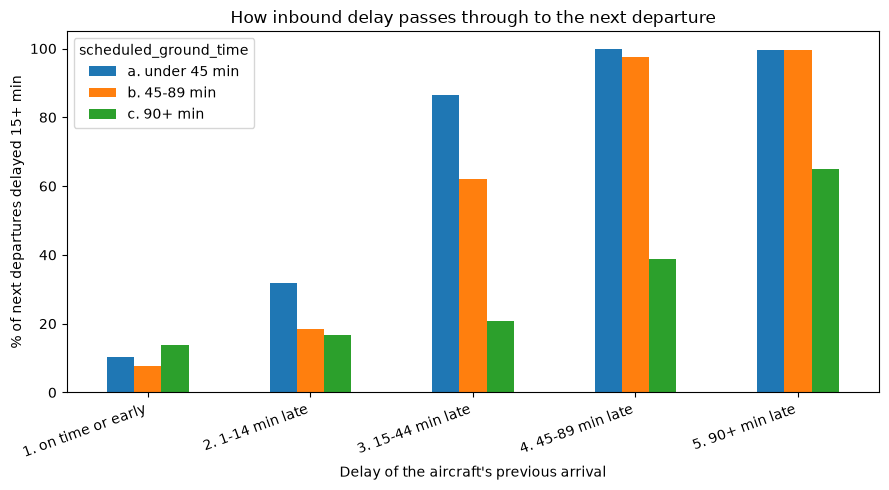

In [3]:
MIN_TURNS = 1000
view = turns[turns["turns"] >= MIN_TURNS]

pivot = view.pivot(index="inbound_delay", columns="scheduled_ground_time",
                   values="pct_next_dep_delayed_15")
pivot.plot(kind="bar", figsize=(9, 5))
plt.ylabel("% of next departures delayed 15+ min")
plt.xlabel("Delay of the aircraft's previous arrival")
plt.title("How inbound delay passes through to the next departure")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "docs" / "delay_propagation.png", dpi=150)
plt.show()

In [4]:
hourly = q("""
SELECT origin, full_date, sched_dep_hour,
       COUNT(*) AS scheduled_deps,
       percentile_cont(0.5) WITHIN GROUP (ORDER BY taxi_out)
           FILTER (WHERE NOT is_cancelled)                        AS median_taxi_out,
       AVG(dep_del15::int) FILTER (WHERE NOT is_cancelled)        AS dep_delay_rate
FROM analytics.v_flights
WHERE sched_dep_hour IS NOT NULL
  AND origin IN (SELECT origin FROM analytics.v_flights
                 GROUP BY origin ORDER BY COUNT(*) DESC LIMIT 15)
GROUP BY origin, full_date, sched_dep_hour
""").astype({"median_taxi_out": float, "dep_delay_rate": float})

hourly = hourly.dropna(subset=["median_taxi_out"])
print(f"{len(hourly):,} airport-day-hour rows")

209,486 airport-day-hour rows


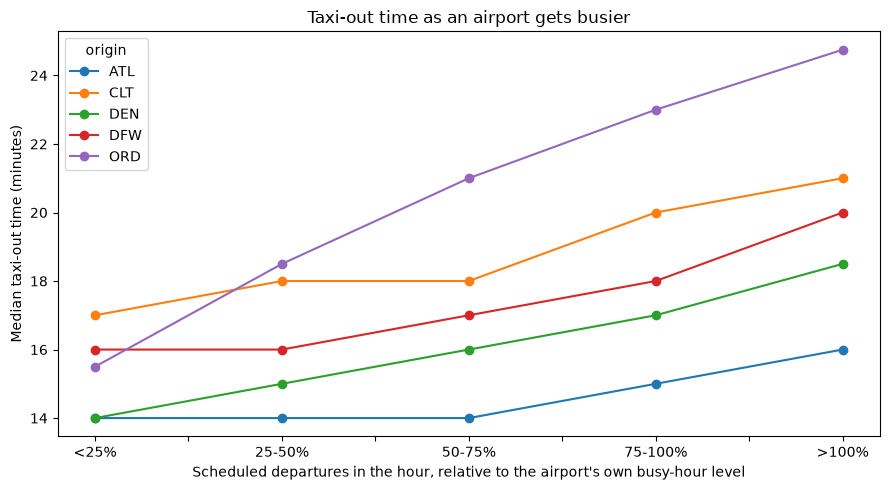

,origin,load_bin,hours,median_taxi_out,median_dep_delay_rate
0,ATL,<25%,1851,14.00,0.090909
1,ATL,25-50%,1397,14.00,0.142857
2,ATL,50-75%,5668,14.00,0.176471
3,ATL,75-100%,4308,15.00,0.171875
4,ATL,>100%,609,16.00,0.131579
10,CLT,<25%,4174,17.00,0.142857
11,CLT,25-50%,3160,18.00,0.260870
12,CLT,50-75%,2134,18.00,0.181818
13,CLT,75-100%,3528,20.00,0.217029
14,CLT,>100%,624,21.00,0.203125


In [5]:
capacity = hourly.groupby("origin")["scheduled_deps"].quantile(0.95).rename("capacity_proxy")
hourly = hourly.join(capacity, on="origin")
hourly["load"] = hourly["scheduled_deps"] / hourly["capacity_proxy"]

bins   = [0, 0.25, 0.5, 0.75, 1.0, 10]
labels = ["<25%", "25-50%", "50-75%", "75-100%", ">100%"]
hourly["load_bin"] = pd.cut(hourly["load"], bins=bins, labels=labels, include_lowest=True)

summary = (hourly.groupby(["origin", "load_bin"], observed=True)
                 .agg(hours=("load", "size"),
                      median_taxi_out=("median_taxi_out", "median"),
                      median_dep_delay_rate=("dep_delay_rate", "median"))
                 .reset_index())

focus = ["ATL", "DFW", "DEN", "ORD", "CLT"]
pivot = (summary[summary["origin"].isin(focus) & (summary["hours"] >= 30)]
         .pivot(index="load_bin", columns="origin", values="median_taxi_out"))

pivot.plot(marker="o", figsize=(9, 5))
plt.ylabel("Median taxi-out time (minutes)")
plt.xlabel("Scheduled departures in the hour, relative to the airport's own busy-hour level")
plt.title("Taxi-out time as an airport gets busier")
plt.tight_layout()
plt.savefig(ROOT / "docs" / "congestion_taxi_out.png", dpi=150)
plt.show()
summary[summary["origin"].isin(focus)]